# Phân tích từng module

In [1]:
import os, time, warnings
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

BASE    = os.path.dirname(os.path.abspath(""))
RESULTS = os.path.join(BASE, "results")
VIDEOS  = os.path.join(BASE, "Data", "wide_view", "videos")
GT_DIR  = os.path.join(BASE, "Data", "wide_view", "annotations")
TEST_VIDEOS = sorted(os.listdir(VIDEOS))[-6:] if os.path.isdir(VIDEOS) else []

mot = pd.read_csv(os.path.join(RESULTS, "mot_test_per_video.csv"), keep_default_na=False)
rt  = pd.read_csv(os.path.join(RESULTS, "runtime_per_video.csv"), keep_default_na=False)
KEY = ["detector", "extractor", "tracker", "gta"]
M   = ["MOTA", "IDF1", "HOTA", "IDs", "FP", "FN"]
S   = mot.groupby(KEY)[M].mean().reset_index()            # trung bình 6 video / cấu hình
E2E = S[S.detector.isin(["YOLO26", "RF-DETR"])]
print(f"{len(E2E)} cấu hình E2ESoTrack + {len(S) - len(E2E)} baseline, mỗi cấu hình 6 video")

# Bảng màu categorical (thứ tự cố định) + xám cho mốc so sánh
BLUE, ORANGE, AQUA, YELLOW, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#9a9a96"
COL_DET = {"YOLO26": BLUE, "RF-DETR": ORANGE}
COL_EXT = {"OSNet": BLUE, "SOLIDER": ORANGE, "Color Histogram": AQUA, "None": GRAY}
COL_TRK = {"ByteTrack": BLUE, "OC-SORT": ORANGE, "StrongSORT": AQUA, "Deep-EIoU": YELLOW}
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e6e3", "grid.linewidth": 0.8,
                     "axes.axisbelow": True, "font.size": 10, "axes.titleweight": "bold"})

def cfg_name(r):
    return f"{r.extractor} · {r.tracker}" + (" · GTA" if r.gta else "")

56 cấu hình E2ESoTrack + 2 baseline, mỗi cấu hình 6 video


## 1. Detector: YOLO26 và RF-DETR

### 1.1 So sánh theo từng cặp cấu hình

YOLO26 tốt hơn RF-DETR ở bao nhiêu / 28 cặp:
  MOTA : 28/28   chênh trung bình +15.94
  IDF1 : 28/28   chênh trung bình +6.01
  HOTA : 28/28   chênh trung bình +5.99
  FP   : 28/28   chênh trung bình -738.17
  FN   : 28/28   chênh trung bình -1899.49


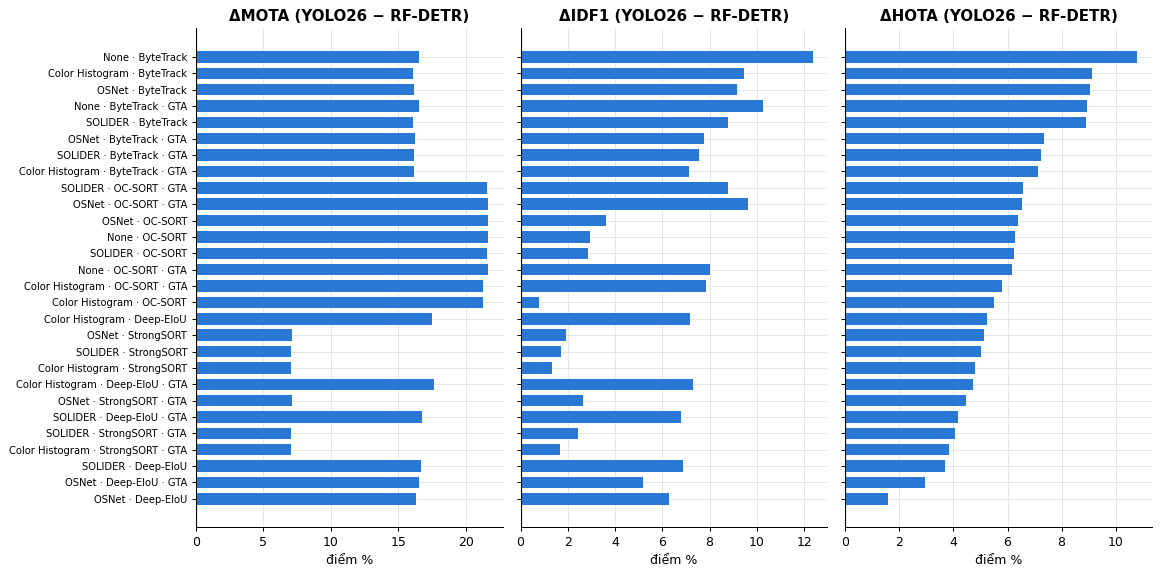

In [2]:
pair = E2E.pivot_table(index=["extractor", "tracker", "gta"], columns="detector", values=M).reset_index()
d = pd.DataFrame({m: pair[(m, "YOLO26")] - pair[(m, "RF-DETR")] for m in M})
d["config"] = [cfg_name(r) for r in pair[["extractor", "tracker", "gta"]].droplevel(1, axis=1).itertuples()]
print("YOLO26 tốt hơn RF-DETR ở bao nhiêu / 28 cặp:")
for m, better in [("MOTA", ">"), ("IDF1", ">"), ("HOTA", ">"), ("FP", "<"), ("FN", "<")]:
    print(f"  {m:5}: {int(((d[m] > 0) if better == '>' else (d[m] < 0)).sum())}/28   "
          f"chênh trung bình {d[m].mean():+.2f}")

fig, axes = plt.subplots(1, 3, figsize=(13, 6.5), sharey=True)
order = d.sort_values("HOTA").config
for ax, m in zip(axes, ["MOTA", "IDF1", "HOTA"]):
    v = d.set_index("config").loc[order, m]
    ax.barh(range(len(v)), v, color=BLUE, height=0.7)
    ax.axvline(0, color="#52514e", lw=1)
    ax.set_title(f"Δ{m} (YOLO26 − RF-DETR)"); ax.set_xlabel("điểm %")
axes[0].set_yticks(range(len(order))); axes[0].set_yticklabels(order, fontsize=8)
plt.tight_layout(); plt.show()

In [3]:
t1 = E2E.groupby("detector")[["MOTA", "IDF1", "HOTA", "FP", "FN"]].mean().round(2)
t1   # Bảng 1 của paper

,MOTA,IDF1,HOTA,FP,FN
detector,,,,,
RF-DETR,49.31,55.17,19.22,1538.25,6758.51
YOLO26,65.26,61.17,25.21,800.08,4859.02


### 1.2 Recall theo kích thước cầu thủ

In [4]:
import sys
sys.path.insert(0, os.path.join(BASE, "PipelineMOT"))
from src.detector import Detector
from src.compute_metrics import load_gt_from_csv, _match_detections

MODELS = os.path.join(BASE, "PipelineMOT", "models")
STEP   = 25                                               # 1 frame / giây
H_BINS = [0, 35, 45, 55, 200]
H_LBL  = ["<35 px", "35–45", "45–55", "≥55 px"]

def eval_detector(det, videos, step=STEP):
    rows, times = [], []
    det.detect(np.zeros((1000, 6500, 3), np.uint8))      # warm-up
    for v in videos:
        gt  = load_gt_from_csv(os.path.join(GT_DIR, os.path.splitext(v)[0] + ".csv"))
        cap = cv2.VideoCapture(os.path.join(VIDEOS, v))
        f = 0
        while True:
            ok = cap.grab()
            if not ok: break
            if f % step == 0:
                _, img = cap.retrieve()
                t0 = time.time(); dets = det.detect(img); times.append(time.time() - t0)
                g = [b[:4] for b in gt.get(f + 1, [])]
                p = [list(b[:4]) for b in dets]
                matches, _, un_p = _match_detections(g, p, 0.5)
                hit = {i for i, _ in matches}
                rows += [dict(video=v, frame=f, kind="gt", h=b[3] - b[1], tp=i in hit) for i, b in enumerate(g)]
                rows += [dict(video=v, frame=f, kind="pred", h=b[3] - b[1], tp=j not in un_p) for j, b in enumerate(p)]
            f += 1
        cap.release()
    return pd.DataFrame(rows), float(np.median(times))

det_res = {}
for name, backend, path in [("YOLO26", "yolo26", "best_yolo26.pt"), ("RF-DETR", "rf_detr", "best_rf_detr.pth")]:
    det_res[name] = eval_detector(Detector(backend=backend, model_path=os.path.join(MODELS, path)), TEST_VIDEOS)

rows = []
for name, (df, t) in det_res.items():
    g, p = df[df.kind == "gt"], df[df.kind == "pred"]
    rows.append({"Detector": name, "GT boxes": len(g), "Recall": g.tp.mean(), "Precision": p.tp.mean(),
                 "FP / frame": (~p.tp).sum() / df.video.nunique() / (750 // STEP),
                 "ms / frame": 1000 * t})
pd.DataFrame(rows).set_index("Detector").round(3)

[Detector] YOLO loaded on cuda


[Detector] RF-DETR loaded


,GT boxes,Recall,Precision,FP / frame,ms / frame
Detector,,,,,
YOLO26,3960,0.853,0.910,1.856,49.330
RF-DETR,3960,0.661,0.801,3.611,100.507


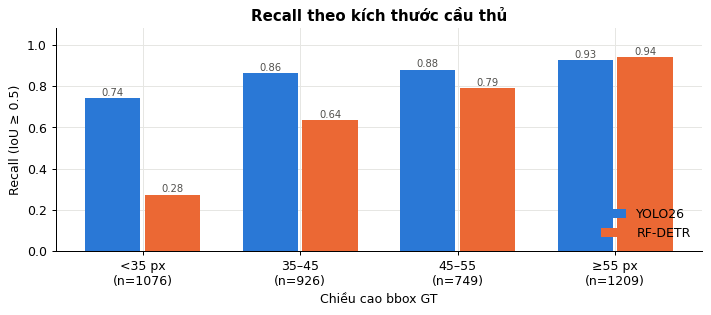

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.6))
w = 0.38
for k, (name, (df, _)) in enumerate(det_res.items()):
    g = df[df.kind == "gt"].copy()
    g["bin"] = pd.cut(g.h, H_BINS, labels=H_LBL, right=False)
    r = g.groupby("bin", observed=False).tp.mean()
    x = np.arange(len(H_LBL)) + (k - 0.5) * w
    ax.bar(x, r.values, width=w - 0.03, color=COL_DET[name], label=name)
    for xi, yi in zip(x, r.values):
        ax.text(xi, yi + 0.01, f"{yi:.2f}", ha="center", fontsize=8, color="#52514e")
n = det_res["YOLO26"][0].query("kind == 'gt'").assign(bin=lambda t: pd.cut(t.h, H_BINS, labels=H_LBL, right=False)).bin.value_counts().reindex(H_LBL)
ax.set_xticks(range(len(H_LBL))); ax.set_xticklabels([f"{l}\n(n={c})" for l, c in zip(H_LBL, n)])
ax.set_ylim(0, 1.08); ax.set_ylabel("Recall (IoU ≥ 0.5)"); ax.set_xlabel("Chiều cao bbox GT")
ax.set_title("Recall theo kích thước cầu thủ"); ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

[Detector] YOLO loaded on cuda


[Detector] RF-DETR loaded


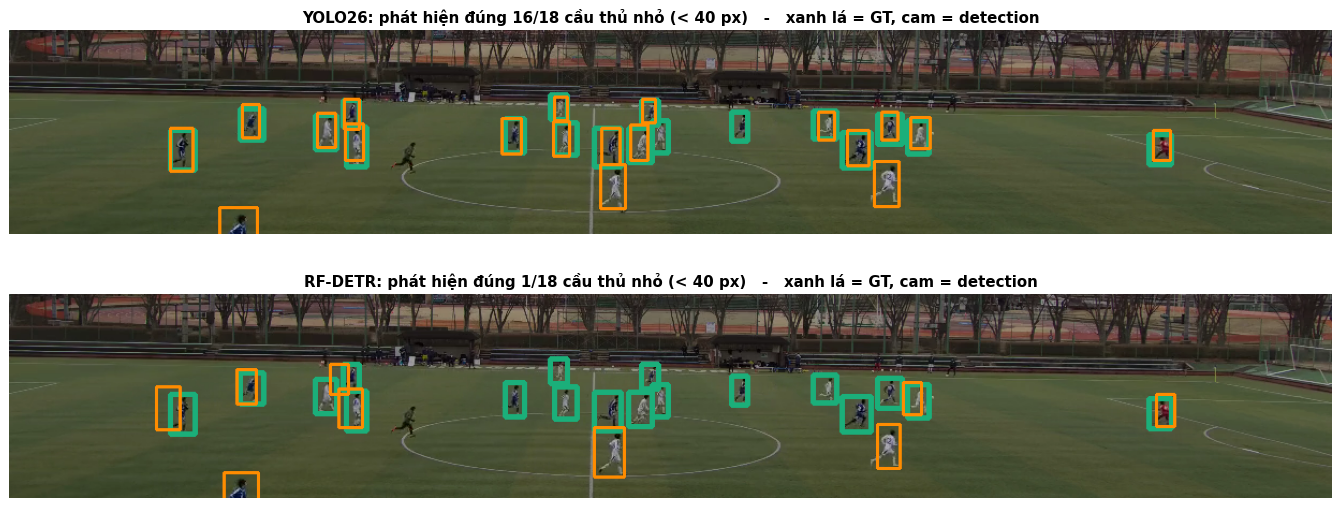

In [6]:
# Minh họa: frame mà RF-DETR bỏ sót nhiều cầu thủ nhất so với YOLO26, zoom vào vùng cầu thủ nhỏ (xa camera)
tp = {k: df[df.kind == "gt"].groupby(["video", "frame"]).tp.sum() for k, (df, _) in det_res.items()}
v, f = (tp["YOLO26"] - tp["RF-DETR"]).idxmax()
cap = cv2.VideoCapture(os.path.join(VIDEOS, v)); cap.set(cv2.CAP_PROP_POS_FRAMES, f); _, img = cap.read(); cap.release()
gt = load_gt_from_csv(os.path.join(GT_DIR, os.path.splitext(v)[0] + ".csv")).get(f + 1, [])
small = [b for b in gt if b[3] - b[1] < 40] or gt
x0 = max(int(min(b[0] for b in small)) - 150, 0); x1 = min(int(max(b[2] for b in small)) + 150, img.shape[1])
y0 = max(int(min(b[1] for b in small)) - 60, 0);  y1 = min(int(max(b[3] for b in small)) + 60, img.shape[0])

fig, axes = plt.subplots(2, 1, figsize=(15, 6.2))
for ax, (name, backend, path) in zip(axes, [("YOLO26", "yolo26", "best_yolo26.pt"), ("RF-DETR", "rf_detr", "best_rf_detr.pth")]):
    dets = Detector(backend=backend, model_path=os.path.join(MODELS, path)).detect(img)
    m, _, _ = _match_detections([b[:4] for b in small], [list(d[:4]) for d in dets], 0.5)
    vis = img.copy()
    for b in small: cv2.rectangle(vis, (int(b[0]), int(b[1])), (int(b[2]), int(b[3])), (122, 175, 27), 3)
    for x_1, y_1, x_2, y_2, _ in dets: cv2.rectangle(vis, (x_1, y_1), (x_2, y_2), (0, 140, 255), 2)
    ax.imshow(cv2.cvtColor(vis[y0:y1, x0:x1], cv2.COLOR_BGR2RGB)); ax.axis("off")
    ax.set_title(f"{name}: phát hiện đúng {len(m)}/{len(small)} cầu thủ nhỏ (< 40 px)   -   xanh lá = GT, cam = detection")
plt.tight_layout(); plt.show()

## 2. Feature extractor

### 2.1 So với không dùng extractor

In [7]:
Y = E2E[E2E.detector == "YOLO26"]
t2 = Y.groupby("extractor")[["MOTA", "IDF1", "HOTA", "IDs"]].mean().round(2)
t2["N"] = Y.groupby("extractor").size()
t2   # Bảng 2 của paper

,MOTA,IDF1,HOTA,IDs,N
extractor,,,,,
Color Histogram,64.60,60.94,24.72,90.21,8
None,68.18,59.71,25.97,13.96,4
OSNet,64.77,61.44,25.10,92.85,8
SOLIDER,64.93,61.87,25.42,68.02,8


In [8]:
# Chỉ ByteTrack và OC-SORT chạy được không cần extractor → so sánh cặp với None
base = Y[Y.extractor == "None"].set_index(["tracker", "gta"])
rows = []
for r in Y[(Y.extractor != "None") & Y.tracker.isin(["ByteTrack", "OC-SORT"])].itertuples():
    b = base.loc[(r.tracker, r.gta)]
    rows.append({"tracker": r.tracker, "GTA": r.gta, "extractor": r.extractor,
                 **{f"Δ{m}": getattr(r, m) - b[m] for m in ["MOTA", "IDF1", "HOTA", "IDs"]}})
dx = pd.DataFrame(rows)
dx.round(2)

,tracker,GTA,extractor,ΔMOTA,ΔIDF1,ΔHOTA,ΔIDs
0,ByteTrack,False,Color Histogram,0.33,0.48,0.28,0.00
1,ByteTrack,True,Color Histogram,0.37,-0.19,-0.17,-8.33
2,OC-SORT,False,Color Histogram,-0.25,-1.52,-0.59,0.00
3,OC-SORT,True,Color Histogram,-0.33,0.55,-0.44,13.50
4,ByteTrack,False,OSNet,0.42,0.56,0.45,0.00
5,ByteTrack,True,OSNet,0.47,-0.04,-0.15,-8.00
6,OC-SORT,False,OSNet,-0.00,0.35,0.12,0.33
7,OC-SORT,True,OSNet,-0.01,0.84,0.27,1.00
8,ByteTrack,False,SOLIDER,0.42,0.70,0.54,0.00
9,ByteTrack,True,SOLIDER,0.47,0.11,-0.01,-8.00


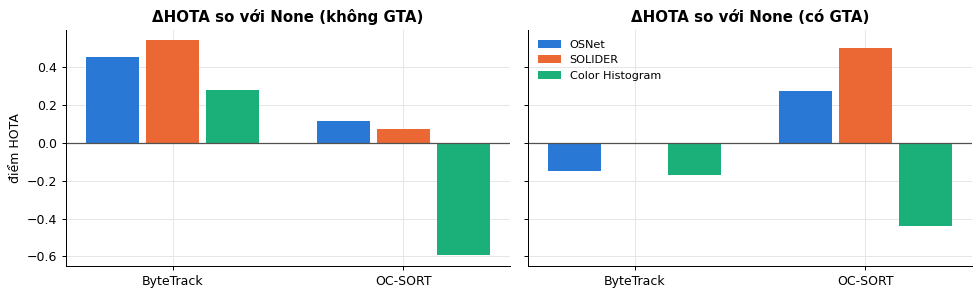

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, gta in zip(axes, [False, True]):
    sub = dx[dx.GTA == gta]
    trk = ["ByteTrack", "OC-SORT"]; exts = ["OSNet", "SOLIDER", "Color Histogram"]; w = 0.26
    for k, e in enumerate(exts):
        vals = [sub[(sub.tracker == t) & (sub.extractor == e)]["ΔHOTA"].item() for t in trk]
        ax.bar(np.arange(2) + (k - 1) * w, vals, width=w - 0.03, color=COL_EXT[e], label=e)
    ax.axhline(0, color="#52514e", lw=1); ax.set_xticks(range(2)); ax.set_xticklabels(trk)
    ax.set_title(f"ΔHOTA so với None ({'có' if gta else 'không'} GTA)")
axes[0].set_ylabel("điểm HOTA"); axes[1].legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()

### 2.2 Kích thước crop

Chiều cao bbox GT: trung vị 44 px, P5–P95 25–100 px
Tỉ lệ bbox cao < 128 px: 99.1%  →  OSNet phải phóng to ~5.8×, SOLIDER ~8.7×


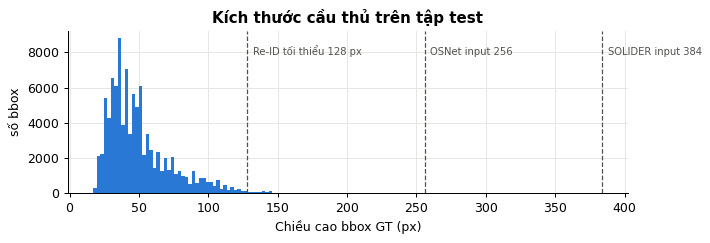

In [10]:
hs = []
for v in TEST_VIDEOS:
    gt = load_gt_from_csv(os.path.join(GT_DIR, os.path.splitext(v)[0] + ".csv"))
    hs += [b[3] - b[1] for boxes in gt.values() for b in boxes]
hs = np.array(hs)
print(f"Chiều cao bbox GT: trung vị {np.median(hs):.0f} px, P5–P95 {np.percentile(hs, 5):.0f}–{np.percentile(hs, 95):.0f} px")
print(f"Tỉ lệ bbox cao < 128 px: {(hs < 128).mean():.1%}  →  OSNet phải phóng to ~{256 / np.median(hs):.1f}×, SOLIDER ~{384 / np.median(hs):.1f}×")

fig, ax = plt.subplots(figsize=(8, 2.8))
ax.hist(hs, bins=60, color=BLUE)
for y, lbl in [(128, "Re-ID tối thiểu 128 px"), (256, "OSNet input 256"), (384, "SOLIDER input 384")]:
    ax.axvline(y, color="#52514e", lw=1, ls="--"); ax.text(y + 4, ax.get_ylim()[1] * 0.85, lbl, fontsize=8, color="#52514e")
ax.set_xlabel("Chiều cao bbox GT (px)"); ax.set_ylabel("số bbox"); ax.set_title("Kích thước cầu thủ trên tập test")
plt.tight_layout(); plt.show()

### 2.3 Độ tách biệt embedding

In [11]:
from sklearn.metrics import roc_auc_score
from src.feature_extractor import FeatureExtractor

def gt_crops(video, frames):
    gt  = load_gt_from_csv(os.path.join(GT_DIR, os.path.splitext(video)[0] + ".csv"))
    cap = cv2.VideoCapture(os.path.join(VIDEOS, video))
    crops, ids, fr = [], [], []
    for f in frames:
        cap.set(cv2.CAP_PROP_POS_FRAMES, f); ok, img = cap.read()
        for x_1, y_1, x_2, y_2, uid in gt.get(f + 1, []):
            c = img[int(y_1):int(y_2), int(x_1):int(x_2)]
            if c.size: crops.append(c); ids.append(uid); fr.append(f)
    cap.release()
    return crops, np.array(ids), np.array(fr)

crops, ids, fr = gt_crops(TEST_VIDEOS[0], range(0, 750, 50))
same  = ids[:, None] == ids[None, :]
valid = np.triu(fr[:, None] != fr[None, :], 1)

extractors = {"OSNet": FeatureExtractor(backend="osnet"),
              "SOLIDER": FeatureExtractor(backend="solider", solider_model_path=os.path.join(MODELS, "swin_small_converted.pth"),
                                          solider_arch="swin_small", solider_semantic_weight=0.2),
              "Color Histogram": FeatureExtractor(backend="color_histogram")}
sims, rows = {}, []
for name, ex in extractors.items():
    ex.extract_batch(crops[:8])                                   # warm-up
    t0 = time.time(); E = np.stack(ex.extract_batch(crops)).astype(np.float32); t = time.time() - t0
    E /= np.linalg.norm(E, axis=1, keepdims=True) + 1e-8
    Sm = E @ E.T
    sims[name] = (Sm[valid & same], Sm[valid & ~same])
    rows.append({"Extractor": name, "ROC-AUC": roc_auc_score(same[valid], Sm[valid]),
                 "sim cùng người": Sm[valid & same].mean(), "sim khác người": Sm[valid & ~same].mean(),
                 "ms / crop": 1000 * t / len(crops)})
print(f"{len(crops)} crops, {valid.sum():,} cặp ({(valid & same).sum():,} cùng người)")
pd.DataFrame(rows).set_index("Extractor").round(3)

Successfully loaded imagenet pretrained weights from "C:\Users\Admin/.cache\torch\checkpoints\osnet_x1_0_imagenet.pth"
** The following layers are discarded due to unmatched keys or layer size: ['classifier.weight', 'classifier.bias']
[FeatureExtractor] OSNet loaded on cuda


Missing: 0 | Unexpected: 8


[FeatureExtractor] SOLIDER (swin_small) loaded on cuda
[FeatureExtractor] Feature dim: 768


330 crops, 50,820 cặp (2,310 cùng người)


,ROC-AUC,sim cùng người,sim khác người,ms / crop
Extractor,,,,
OSNet,0.778,0.764,0.688,2.609
SOLIDER,0.826,0.833,0.695,10.311
Color Histogram,0.746,0.631,0.445,0.026


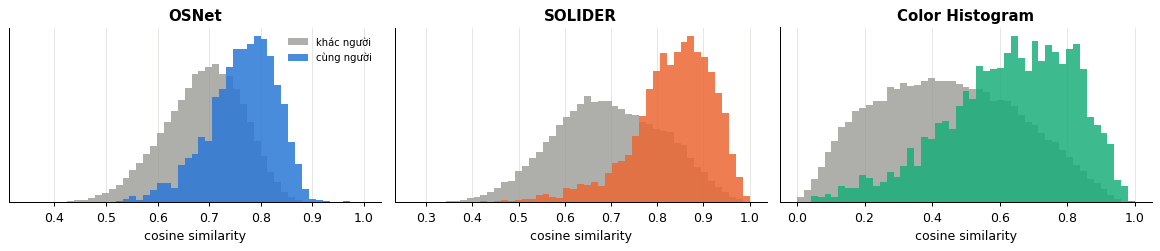

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(13, 2.9), sharey=False)
for ax, (name, (s_same, s_diff)) in zip(axes, sims.items()):
    bins = np.linspace(min(s_same.min(), s_diff.min()), 1, 50)
    ax.hist(s_diff, bins=bins, density=True, color=GRAY, alpha=0.8, label="khác người")
    ax.hist(s_same, bins=bins, density=True, color=COL_EXT[name], alpha=0.85, label="cùng người")
    ax.set_title(name); ax.set_xlabel("cosine similarity"); ax.set_yticks([])
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

## 3. Tracker

In [13]:
Yn = Y[~Y.gta].copy()
Yn["variant"] = np.where(Yn.extractor == "None", "None", "+Extractor (TB 3)")
t3 = Yn.groupby(["tracker", "variant"])[M].mean().round(2)
t3   # một phần Bảng 3 của paper

MOTA   IDF1   HOTA     IDs       FP       FN
tracker    variant                                                         
ByteTrack  +Extractor (TB 3)  68.72  66.84  28.82    0.83   716.78  4442.83
           None               68.33  66.26  28.40    0.83   715.50  4508.67
Deep-EIoU  +Extractor (TB 3)  64.90  67.25  22.65  314.44  1100.11  4377.61
OC-SORT    +Extractor (TB 3)  68.04  47.86  19.58   10.78   787.94  4475.00
           None               68.13  48.24  19.71   10.67   793.00  4454.83
StrongSORT +Extractor (TB 3)  57.46  58.34  22.22    0.89   626.06  6392.17

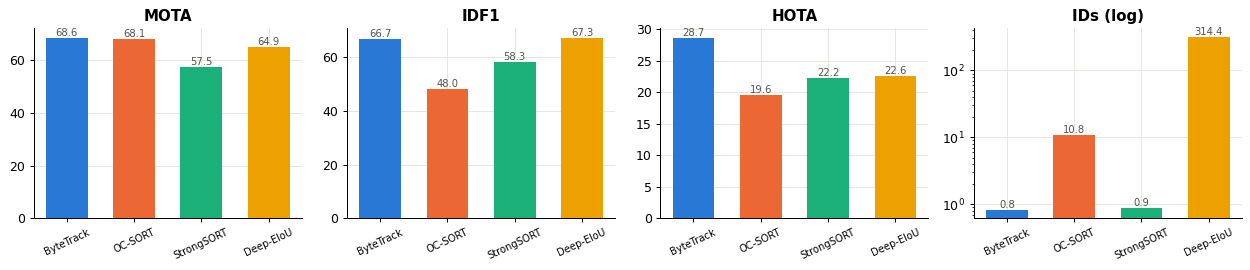

In [14]:
avg = Yn.groupby("tracker")[["MOTA", "IDF1", "HOTA", "IDs", "FN"]].mean().reindex(list(COL_TRK))
fig, axes = plt.subplots(1, 4, figsize=(14, 3.1))
for ax, m in zip(axes, ["MOTA", "IDF1", "HOTA", "IDs"]):
    ax.bar(avg.index, avg[m], color=[COL_TRK[t] for t in avg.index], width=0.62)
    for i, val in enumerate(avg[m]):
        ax.text(i, val, f"{val:.1f}", ha="center", va="bottom", fontsize=8, color="#52514e")
    ax.set_title(m + (" (log)" if m == "IDs" else "")); ax.tick_params(axis="x", rotation=25, labelsize=8)
    if m == "IDs": ax.set_yscale("log")
plt.tight_layout(); plt.show()

In [15]:
# Độ ổn định: HOTA từng video của mỗi tracker (biến thể tốt nhất, không GTA)
best_var = Yn.loc[Yn.groupby("tracker").HOTA.idxmax(), ["tracker", "extractor"]]
pv = mot.merge(best_var.assign(gta=False), on=["tracker", "extractor", "gta"]).query("detector == 'YOLO26'")
tab = pv.pivot_table(index="video", columns="tracker", values="HOTA")[list(COL_TRK)]
tab.index = [v.split("_")[-2] + "–" + v.split("_")[-1][:4] for v in tab.index]
print("Biến thể tốt nhất:", dict(best_var.values)); print("Số video ByteTrack đứng đầu HOTA:", int((tab.idxmax(axis=1) == "ByteTrack").sum()), "/ 6")
tab.round(2)

Biến thể tốt nhất: {'ByteTrack': 'SOLIDER', 'Deep-EIoU': 'SOLIDER', 'OC-SORT': 'OSNet', 'StrongSORT': 'OSNet'}
Số video ByteTrack đứng đầu HOTA: 5 / 6


tracker,ByteTrack,OC-SORT,StrongSORT,Deep-EIoU
1800–1830,29.50,20.15,22.77,22.67
1830–1860,38.14,24.73,30.07,31.67
1860–1890,27.31,18.51,21.59,18.42
1890–1920,31.94,21.18,25.53,35.75
1920–1950,26.56,16.96,19.21,18.09
1950–1980,20.19,17.45,14.78,15.04


## 4. GTA

### 4.1 Trước và sau GTA

In [16]:
g = Y.pivot_table(index=["extractor", "tracker"], columns="gta", values=["MOTA", "IDF1", "HOTA", "IDs"])
dg = pd.DataFrame({f"Δ{m}": g[(m, True)] - g[(m, False)] for m in ["MOTA", "IDF1", "HOTA", "IDs"]}).round(2)
print("HOTA tăng ở", int((dg["ΔHOTA"] > 0).sum()), "/", len(dg), "cấu hình; MOTA đổi trung bình", f"{dg['ΔMOTA'].mean():+.2f}")
dg

HOTA tăng ở 14 / 14 cấu hình; MOTA đổi trung bình -0.03


ΔMOTA  ΔIDF1  ΔHOTA   ΔIDs
extractor       tracker                               
Color Histogram ByteTrack   -0.02  -1.04   2.49   3.17
                Deep-EIoU    0.12  -0.22   3.00 -19.33
                OC-SORT     -0.21  12.27   4.86  34.83
                StrongSORT  -0.03   0.99   3.36   5.33
None            ByteTrack   -0.07  -0.37   2.94  11.50
                OC-SORT     -0.13  10.20   4.70  21.33
OSNet           ByteTrack   -0.02  -0.97   2.34   3.50
                Deep-EIoU    0.21  -1.41   3.70 -35.17
                OC-SORT     -0.13  10.68   4.86  22.00
                StrongSORT  -0.04   1.18   3.67   6.83
SOLIDER         ByteTrack   -0.02  -0.96   2.39   3.50
                Deep-EIoU    0.03  -0.24   2.96  -4.33
                OC-SORT     -0.12  10.42   5.13  19.67
                StrongSORT  -0.04   1.56   3.55   7.00

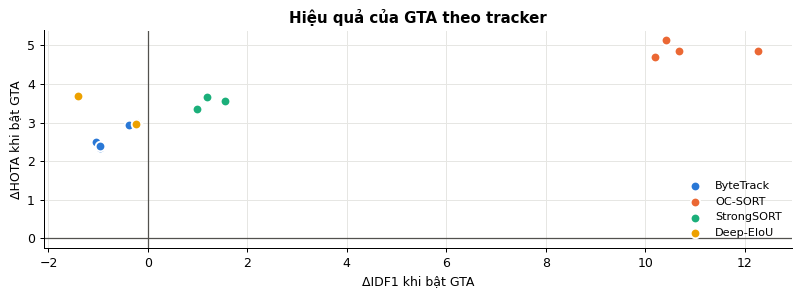

In [17]:
fig, ax = plt.subplots(figsize=(9, 3.4))
dgt = dg.reset_index()
for k, t in enumerate(COL_TRK):
    sub = dgt[dgt.tracker == t]
    ax.scatter(sub["ΔIDF1"], sub["ΔHOTA"], s=60, color=COL_TRK[t], label=t, edgecolor="white", linewidth=1.5)
ax.axhline(0, color="#52514e", lw=1); ax.axvline(0, color="#52514e", lw=1)
ax.set_xlabel("ΔIDF1 khi bật GTA"); ax.set_ylabel("ΔHOTA khi bật GTA"); ax.set_title("Hiệu quả của GTA theo tracker")
ax.legend(frameon=False, fontsize=9, loc="lower right"); plt.tight_layout(); plt.show()

### 4.2 Số ID trên mỗi clip

In [18]:
import pickle
P = os.path.join(BASE, "Output", "pitch_eval")
if os.path.exists(os.path.join(P, "tracks_e2e_fast.pkl")):
    fast = pickle.load(open(os.path.join(P, "tracks_e2e_fast.pkl"), "rb"))
    best = pickle.load(open(os.path.join(P, "tracks_e2e_best.pkl"), "rb"))
    rows = []
    for v in fast:
        gt = load_gt_from_csv(os.path.join(GT_DIR, os.path.splitext(v)[0] + ".csv"))
        n_gt = len({b[4] for boxes in gt.values() for b in boxes})
        long = lambda tr: sum(len(t["frames"]) >= 375 for t in tr.values())
        rows.append({"clip": v.split("_")[-2] + "–" + v.split("_")[-1][:4], "cầu thủ (GT)": n_gt,
                     "ID trước GTA": len(fast[v]), "ID sau GTA": len(best[v]),
                     "ID dài ≥ 15 s trước": long(fast[v]), "ID dài ≥ 15 s sau": long(best[v])})
    display(pd.DataFrame(rows).set_index("clip"))
else:
    print("Chưa có tracks - chạy: python PipelineMOT/save_pitch_tracks.py")

,cầu thủ (GT),ID trước GTA,ID sau GTA,ID dài ≥ 15 s trước,ID dài ≥ 15 s sau
clip,,,,,
0720–0750,22,53,23,15,18
0750–0780,22,43,21,14,17
0780–0810,22,44,24,19,21
0810–0840,22,40,28,18,21
0840–0870,22,44,25,13,18
0870–0900,22,44,26,18,20


### 4.3 Tọa độ trên sân so với GNSS

In [19]:
pe = pd.read_csv(os.path.join(RESULTS, "pitch_eval_summary.csv")).set_index("Pipeline")
pv = pd.read_csv(os.path.join(RESULTS, "pitch_eval_per_video.csv"))
w  = pv.pivot_table(index="video", columns="Pipeline", values=["Pitch-HOTA", "E_1to1"])
print("GTA cải thiện Pitch-HOTA ở", int((w[("Pitch-HOTA", "YOLO26 + ByteTrack + GTA")] > w[("Pitch-HOTA", "YOLO26 + ByteTrack")]).sum()), "/ 6 clip,",
      "E_1to1 ở", int((w[("E_1to1", "YOLO26 + ByteTrack + GTA")] < w[("E_1to1", "YOLO26 + ByteTrack")]).sum()), "/ 6 clip")
pe[["Pitch-HOTA", "E_1to1"]]

GTA cải thiện Pitch-HOTA ở 5 / 6 clip, E_1to1 ở 6 / 6 clip


,Pitch-HOTA,E_1to1
Pipeline,,
Oracle (GT boxes),64.09,3.53
Baseline,16.34,5.34
Baseline (trained),35.22,6.01
YOLO26 + ByteTrack,47.60,4.80
YOLO26 + ByteTrack + GTA,48.88,4.53


## 5. Độ chính xác và thời gian chạy

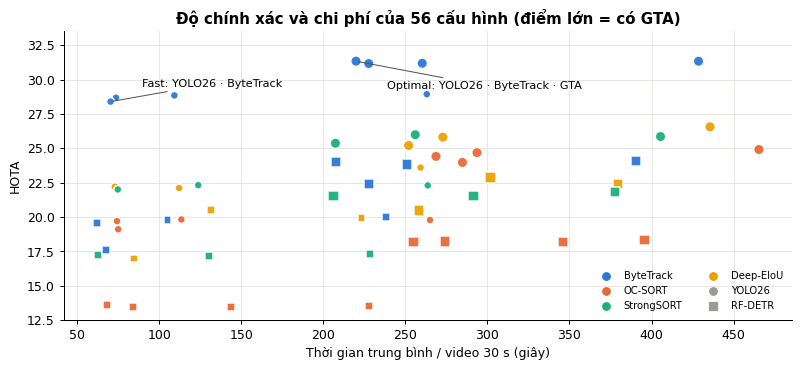

,detector,extractor,tracker,gta,s / video,HOTA
37,YOLO26,None,ByteTrack,True,219.96,31.34
49,YOLO26,SOLIDER,ByteTrack,True,428.63,31.33
41,YOLO26,OSNet,ByteTrack,True,260.31,31.19
29,YOLO26,Color Histogram,ByteTrack,True,227.69,31.17
48,YOLO26,SOLIDER,ByteTrack,False,263.07,28.94
40,YOLO26,OSNet,ByteTrack,False,109.28,28.85
28,YOLO26,Color Histogram,ByteTrack,False,73.72,28.68
36,YOLO26,None,ByteTrack,False,70.42,28.40


In [20]:
r = rt.copy()
r["gta"] = False
on = r.groupby(["detector", "extractor", "tracker"])[["online_s", "solider_extract_s", "gta_refine_s"]].mean().reset_index()
rows = []
for x in on.itertuples():
    for gta in (False, True):
        sec = x.online_s + (x.solider_extract_s + x.gta_refine_s if gta else 0)
        h = S[(S.detector == x.detector) & (S.extractor == x.extractor) & (S.tracker == x.tracker) & (S.gta == gta)].HOTA
        rows.append({"detector": x.detector, "extractor": x.extractor, "tracker": x.tracker, "gta": gta, "s / video": sec, "HOTA": h.item()})
perf = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(9, 4.2))
for det, mk in [("YOLO26", "o"), ("RF-DETR", "s")]:
    sub = perf[perf.detector == det]
    ax.scatter(sub["s / video"], sub.HOTA, s=[70 if g else 40 for g in sub.gta], marker=mk,
               color=[COL_TRK[t] for t in sub.tracker], edgecolor="white", linewidth=1.2, alpha=0.95)
for name, q in [("Optimal: YOLO26 · ByteTrack · GTA", "detector=='YOLO26' & extractor=='None' & tracker=='ByteTrack' & gta"),
                ("Fast: YOLO26 · ByteTrack", "detector=='YOLO26' & extractor=='None' & tracker=='ByteTrack' & not gta")]:
    p = perf.query(q).iloc[0]
    ax.annotate(name, (p["s / video"], p.HOTA), xytext=(25, -22 if p.gta else 12), textcoords="offset points", fontsize=9,
                arrowprops=dict(arrowstyle="-", color="#52514e", lw=0.8))
from matplotlib.lines import Line2D
h = [Line2D([], [], marker="o", ls="", color=c, label=t) for t, c in COL_TRK.items()]
h += [Line2D([], [], marker=m, ls="", color=GRAY, label=d) for d, m in [("YOLO26", "o"), ("RF-DETR", "s")]]
ax.legend(handles=h, frameon=False, fontsize=8, ncol=2, loc="lower right")
ax.set_ylim(12.5, 33.5); ax.set_xlabel("Thời gian trung bình / video 30 s (giây)"); ax.set_ylabel("HOTA")
ax.set_title("Độ chính xác và chi phí của 56 cấu hình (điểm lớn = có GTA)")
plt.tight_layout(); plt.show()
perf.sort_values("HOTA", ascending=False).head(8).round(2)